In [1]:
import numpy as np

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
food = pd.read_csv('grocerydb.csv')

In [3]:
food

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.893000,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.893000,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.718400,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.718400,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.893000,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26245,"Sam's Choice Creamy Honey Almond Butter, 12 oz",Walmart,spread-squeeze,Sam's Choice,0.503963,2.0,4.98,0.002465,340.194000,18.750000,50.000000,25.000000,6.250000,9.375000,0.203125,0.000000
26246,"Nutella and Go Snack Packs, Hazelnut Spread & ...",Walmart,spread-squeeze,Nutella,0.738611,3.0,4.98,NaN,NaN,7.407407,24.074074,66.666667,40.740741,3.703704,0.000000,0.011111
26247,"Sabra Dark Chocolate Dessert Dip & Spread, 8 oz",Walmart,spread-squeeze,Sabra,0.829611,3.0,NaN,NaN,226.796000,3.571429,16.071429,35.714286,21.428571,3.571429,0.142857,0.000000
26248,"MaraNatha, No Stir Peanut Butter, 1.15 oz Packets",Walmart,spread-squeeze,MaraNatha,0.609444,2.0,0.78,0.003828,32.601925,25.000000,53.125000,15.625000,3.125000,6.250000,0.203125,0.000000


In [4]:
food.dtypes

name                     object
store                    object
category                 object
brand                    object
FPro                    float64
FPro_class              float64
price                   float64
price percal            float64
package_weight          float64
Protein                 float64
Total Fat               float64
Carbohydrate            float64
Sugars, total           float64
Fiber, total dietary    float64
Sodium                  float64
Cholesterol             float64
dtype: object

**Rename Columns**

In [5]:
food = food.rename(columns={"FPro": "Food Processing Score", "FPro_class": "Food Processing Classification Group", "price percal": "Price Per Calorie", "Sugars, total": "Total Sugar Content", "Fiber, total dietary": "Dietary Fiber Content"})

In [6]:
food["Food Processing Classification Group"]

0        3.0
1        3.0
2        3.0
3        0.0
4        3.0
        ... 
26245    2.0
26246    3.0
26247    3.0
26248    2.0
26249    2.0
Name: Food Processing Classification Group, Length: 26250, dtype: float64

**Check for null values**

In [7]:
nulls = food.isnull().sum()

In [8]:
nulls

name                                       0
store                                      0
category                                   0
brand                                     69
Food Processing Score                      0
Food Processing Classification Group       0
price                                   4030
Price Per Calorie                       5470
package_weight                          1275
Protein                                    0
Total Fat                                  0
Carbohydrate                               0
Total Sugar Content                        9
Dietary Fiber Content                      9
Sodium                                     0
Cholesterol                                0
dtype: int64

In [9]:
food = food.dropna()

In [10]:
food

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,Total Fat,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.893000,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.893000,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.718400,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.718400,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.893000,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26242,"Great Value Powdered Peanut Butter, 30 oz",Walmart,spread-squeeze,Great Value,0.753639,3.0,9.98,0.002816,850.485000,50.000000,12.500000,33.333333,0.000000,8.333333,0.791667,0.000000
26243,Jif Natural Creamy Peanut Butter Spread Twin P...,Walmart,spread-squeeze,Jif,0.496722,2.0,10.00,0.000766,2267.960000,21.212121,48.484848,24.242424,6.060606,9.090909,0.242424,0.000000
26245,"Sam's Choice Creamy Honey Almond Butter, 12 oz",Walmart,spread-squeeze,Sam's Choice,0.503963,2.0,4.98,0.002465,340.194000,18.750000,50.000000,25.000000,6.250000,9.375000,0.203125,0.000000
26248,"MaraNatha, No Stir Peanut Butter, 1.15 oz Packets",Walmart,spread-squeeze,MaraNatha,0.609444,2.0,0.78,0.003828,32.601925,25.000000,53.125000,15.625000,3.125000,6.250000,0.203125,0.000000


**Round Numerica Content to two after the decimal place for the following columns**
- Food Processing Score 
- Price Per Calorie 
- Package WEight
- protein
- Total Fat
- Carbohydrate
- Total Sugar Content
- Dietary Fiber Content
- Sodium
- Choldestrol

In [11]:
food["Price Per Calorie"] = food["Price Per Calorie"].round(2)

In [12]:
food["package_weight"] = food["package_weight"].round(2)

In [13]:
food["Food Processing Score"] = food["Food Processing Score"].round(3)

In [14]:
food["Protein"] = food["Protein"].round(2)

In [15]:
food["Total Fat"] = food["Total Fat"].round(2)

In [16]:
food["Carbohydrate"] = food["Carbohydrate"].round(2)

In [17]:
food["Total Sugar Content"] = food["Total Sugar Content"].round(2)

In [18]:
food["Dietary Fiber Content"] = food["Dietary Fiber Content"].round(2)

In [19]:
food["Sodium"] = food["Sodium"].round(2)

In [20]:
food["Cholesterol"] = food["Cholesterol"].round(2)

In [21]:
food

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,Total Fat,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,3.03,12.12,9.09,0.00,0.08,0.01
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,3.03,12.12,9.09,0.00,0.08,0.01
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,0.55,13.19,7.69,2.20,0.01,0.00
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,7.69,15.38,8.79,3.30,0.00,0.00
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,1.01,14.14,6.06,2.02,0.05,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26242,"Great Value Powdered Peanut Butter, 30 oz",Walmart,spread-squeeze,Great Value,0.754,3.0,9.98,0.00,850.48,50.00,12.50,33.33,0.00,8.33,0.79,0.00
26243,Jif Natural Creamy Peanut Butter Spread Twin P...,Walmart,spread-squeeze,Jif,0.497,2.0,10.00,0.00,2267.96,21.21,48.48,24.24,6.06,9.09,0.24,0.00
26245,"Sam's Choice Creamy Honey Almond Butter, 12 oz",Walmart,spread-squeeze,Sam's Choice,0.504,2.0,4.98,0.00,340.19,18.75,50.00,25.00,6.25,9.38,0.20,0.00
26248,"MaraNatha, No Stir Peanut Butter, 1.15 oz Packets",Walmart,spread-squeeze,MaraNatha,0.609,2.0,0.78,0.00,32.60,25.00,53.12,15.62,3.12,6.25,0.20,0.00


In [22]:
def classification_group(row):
    classificationgroup = row["Food Processing Classification Group"]
    if classificationgroup == 0.0:
        return "Unprocessed or minimally processed foods"
    elif classificationgroup == 1.0:
        return "Processed culinary ingredients"
    elif classificationgroup == 2.0:
        return "Processed foods"
    elif classificationgroup == 3.0:
        return "Ultra-processed food and drink products"
    else:
        return "Not Applicable"

In [23]:
food["Food Processing Group"] = food.apply(classification_group, axis=1)

In [24]:
food["Food Processing Group"]

0         Ultra-processed food and drink products
1         Ultra-processed food and drink products
2         Ultra-processed food and drink products
3        Unprocessed or minimally processed foods
4         Ultra-processed food and drink products
                           ...                   
26242     Ultra-processed food and drink products
26243                             Processed foods
26245                             Processed foods
26248                             Processed foods
26249                             Processed foods
Name: Food Processing Group, Length: 20717, dtype: object

In [25]:
food["Processed Food or Non Processed Food"] = np.where(food["Food Processing Group"] != "Unprocessed or minimally processed foods", "Processed Food", "Unprocessed Food")

In [26]:
food["Processed Food or Non Processed Food"]

0          Processed Food
1          Processed Food
2          Processed Food
3        Unprocessed Food
4          Processed Food
               ...       
26242      Processed Food
26243      Processed Food
26245      Processed Food
26248      Processed Food
26249      Processed Food
Name: Processed Food or Non Processed Food, Length: 20717, dtype: object

In [27]:
food["Organic"] = np.where(food["name"].str.contains("Organic", case=False, na=False),
                           "Organic", "Non-Organic")

In [28]:
food["Organic"]

0            Organic
1            Organic
2            Organic
3            Organic
4            Organic
            ...     
26242    Non-Organic
26243    Non-Organic
26245    Non-Organic
26248    Non-Organic
26249    Non-Organic
Name: Organic, Length: 20717, dtype: object

In [29]:
bins= [0.00, 0.250, 0.50, 0.750, 1.00]

In [30]:
food["Food Processing Score Bins"] = pd.cut(food["Food Processing Score"], bins=bins, labels=False, include_lowest=True)

In [31]:
food

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,Total Fat,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,3.03,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,3.03,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,0.55,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,7.69,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,1.01,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26242,"Great Value Powdered Peanut Butter, 30 oz",Walmart,spread-squeeze,Great Value,0.754,3.0,9.98,0.00,850.48,50.00,12.50,33.33,0.00,8.33,0.79,0.00,Ultra-processed food and drink products,Processed Food,Non-Organic,3
26243,Jif Natural Creamy Peanut Butter Spread Twin P...,Walmart,spread-squeeze,Jif,0.497,2.0,10.00,0.00,2267.96,21.21,48.48,24.24,6.06,9.09,0.24,0.00,Processed foods,Processed Food,Non-Organic,1
26245,"Sam's Choice Creamy Honey Almond Butter, 12 oz",Walmart,spread-squeeze,Sam's Choice,0.504,2.0,4.98,0.00,340.19,18.75,50.00,25.00,6.25,9.38,0.20,0.00,Processed foods,Processed Food,Non-Organic,2
26248,"MaraNatha, No Stir Peanut Butter, 1.15 oz Packets",Walmart,spread-squeeze,MaraNatha,0.609,2.0,0.78,0.00,32.60,25.00,53.12,15.62,3.12,6.25,0.20,0.00,Processed foods,Processed Food,Non-Organic,2


**Among Organic Food, create a swarm plot for the Food Processing Score as well as the Price with store being the color**
- what trends can you pick up on
- Are there any outliers if so where
- Are do the majority of the data plots live for organic and non organic foods

In [32]:
import seaborn as sns

In [33]:
organic = food[food["Organic"] == "Organic"]

In [34]:
organic

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,Total Fat,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,3.03,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,3.03,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,0.55,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,7.69,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,1.01,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26145,Organic Dark Roasted Creamy Peanut Butter Spre...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.488,2.0,6.69,0.00,453.59,25.00,53.12,15.62,3.12,9.38,0.17,0.00,Processed foods,Processed Food,Organic,1
26146,Organic Dark Roasted Crunchy Peanut Butter Spr...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.477,2.0,6.69,0.00,453.59,24.24,54.55,15.15,3.03,9.09,0.15,0.00,Processed foods,Processed Food,Organic,1
26177,"Organic Sunflower Butter, 16 oz",WholeFoods,spread-squeeze,SunButter,0.168,0.0,8.99,0.00,453.59,21.88,56.25,15.62,3.12,9.38,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,0
26208,"Nutiva Organic Hazelnut Spread, Dark Chocolate...",Walmart,spread-squeeze,Nutiva,0.443,0.0,4.97,0.00,368.54,8.11,37.84,48.65,32.43,18.92,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1


In [35]:
food["Organic"].value_counts()

Organic
Non-Organic    18246
Organic         2471
Name: count, dtype: int64

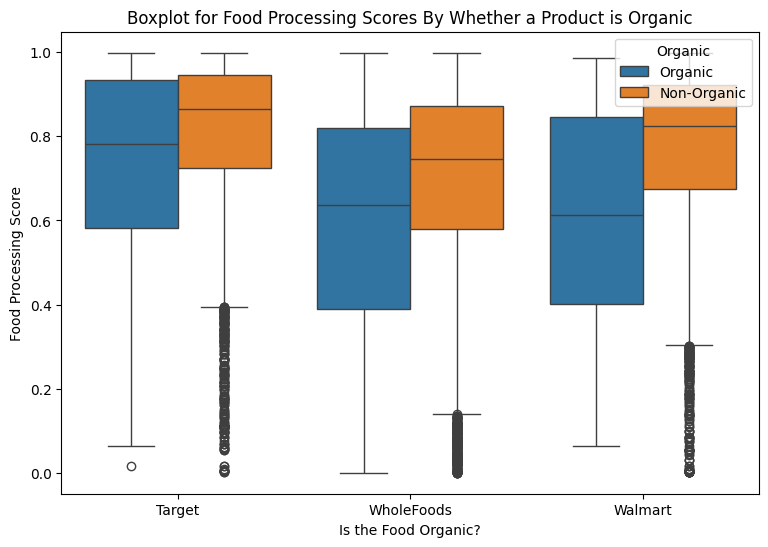

In [36]:
plt.figure(figsize=(9, 6))
plt.title("Boxplot for Food Processing Scores By Whether a Product is Organic")
sns.boxplot(data=food, x="store", y="Food Processing Score", hue="Organic")
plt.xlabel("Is the Food Organic?")
plt.ylabel("Food Processing Score")
plt.legend(title="Organic", loc="upper right")
plt.show()

In [37]:
organic["category"].value_counts()

category
produce-beans-wf           291
produce-packaged           202
cereal                     118
soup-stew                  111
snacks-bars                 92
milk-milk-substitute        84
prepared-meals-dishes       81
dressings                   80
snacks-mixes-crackers       78
dairy-yogurt-drink          78
bread                       74
pastry-chocolate-candy      69
sauce-all                   68
baby-food                   68
nuts-seeds-wf               63
drink-juice                 62
meat-packaged               58
cheese                      56
snacks-chips                47
spread-squeeze              45
cookies-biscuit             42
rice-grains-wf              41
baking                      39
snacks-dips-salsa           38
drink-juice-wf              37
pasta-noodles               37
ice-cream-dessert           36
spices-seasoning            33
drink-shakes-other          29
rolls-buns-wraps            28
snacks-nuts-seeds           27
eggs-wf                     26

In [38]:
organic["Food or Drink"] = np.where(organic["category"].str.contains("milk-milk-substitute|dairy-yogurt-drink|drink-juice|drink-juice-wf|drink-shakes-other|drink-coffee|drink-tea|drink-soft-energy-mixes", case=False, na=False),
                           "Drink", "Food")

C:\Users\alexh\AppData\Local\Temp\ipykernel_53884\3432817780.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  organic["Food or Drink"] = np.where(organic["category"].str.contains("milk-milk-substitute|dairy-yogurt-drink|drink-juice|drink-juice-wf|drink-shakes-other|drink-coffee|drink-tea|drink-soft-energy-mixes", case=False, na=False),


In [39]:
numerics = food[['Food Processing Score', 'price', 'Price Per Calorie', 'package_weight', 'Protein', 'Total Fat', 'Carbohydrate', 'Total Sugar Content', 'Dietary Fiber Content', 'Sodium', 'Cholesterol']]

In [40]:
numerics.corr()

,Food Processing Score,price,Price Per Calorie,package_weight,Protein,Total Fat,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol
Food Processing Score,1.000000,-0.130527,-0.158385,-0.025408,-0.158028,0.068369,0.410798,0.344170,-0.069955,0.005832,-0.010377
price,-0.130527,1.000000,0.096384,0.072432,0.223130,0.114622,-0.104178,-0.034182,0.090392,-0.004083,-0.000076
Price Per Calorie,-0.158385,0.096384,1.000000,-0.008201,-0.045592,-0.059341,-0.071332,-0.044691,-0.034042,-0.000593,-0.001560
package_weight,-0.025408,0.072432,-0.008201,1.000000,-0.028783,-0.037414,-0.038485,-0.030104,-0.036660,0.000542,-0.001240
Protein,-0.158028,0.223130,-0.045592,-0.028783,1.000000,0.251103,-0.074436,-0.178982,0.185336,0.000459,0.022425
Total Fat,0.068369,0.114622,-0.059341,-0.037414,0.251103,1.000000,0.067905,0.074156,0.177232,-0.004651,0.024605
Carbohydrate,0.410798,-0.104178,-0.071332,-0.038485,-0.074436,0.067905,1.000000,0.512916,0.298320,0.003853,-0.010963
Total Sugar Content,0.344170,-0.034182,-0.044691,-0.030104,-0.178982,0.074156,0.512916,1.000000,0.022291,-0.003204,0.002539
Dietary Fiber Content,-0.069955,0.090392,-0.034042,-0.036660,0.185336,0.177232,0.298320,0.022291,1.000000,-0.001104,-0.008885
Sodium,0.005832,-0.004083,-0.000593,0.000542,0.000459,-0.004651,0.003853,-0.003204,-0.001104,1.000000,0.000905


In [41]:
WholeFoods = food[food["store"] == "WholeFoods"]

In [42]:
import matplotlib.patches as mpatches

C:\Users\alexh\AppData\Local\Temp\ipykernel_53884\1226530738.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=WholeFoods, x="Food Processing Group", order=order, palette=palette)


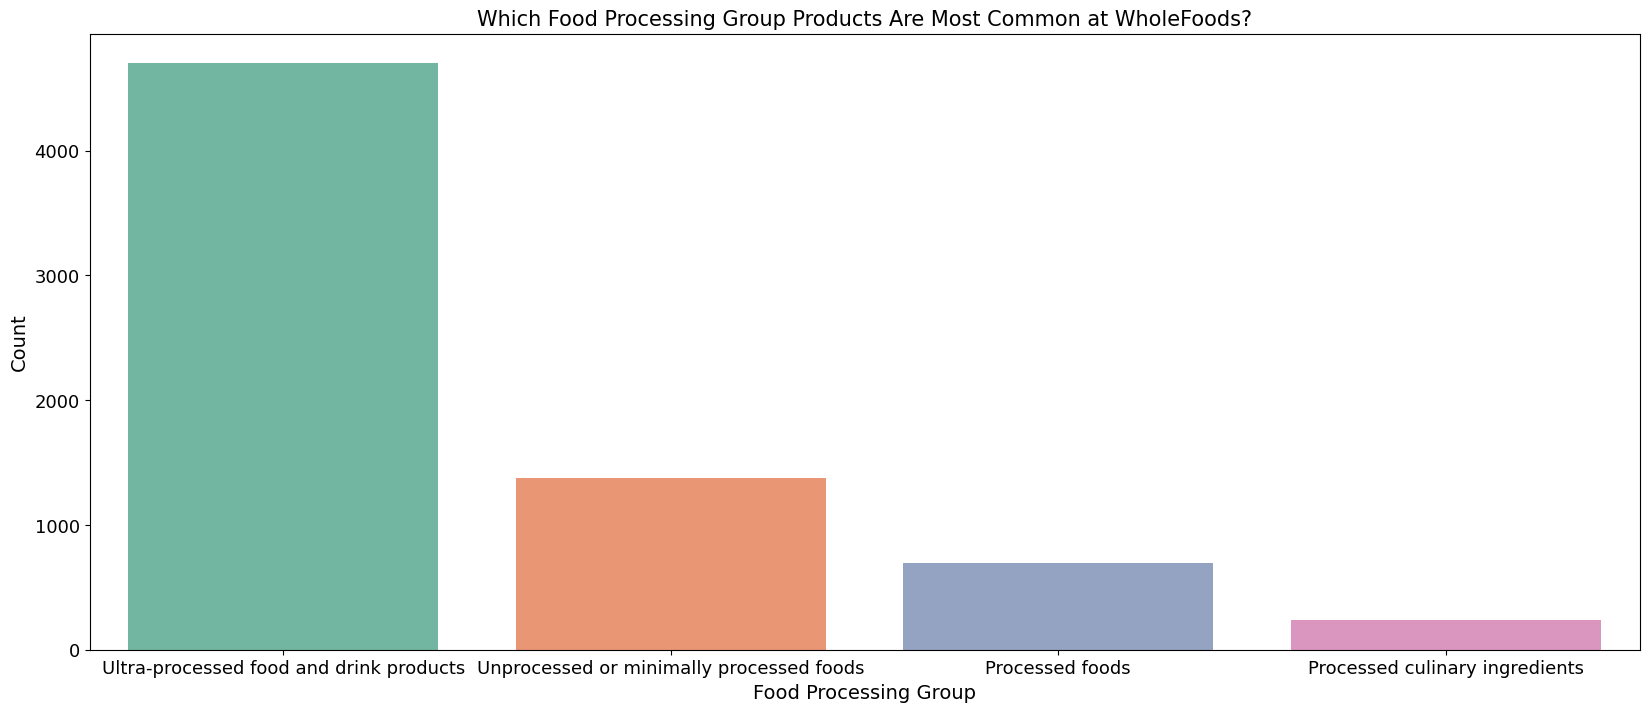

In [43]:
order = WholeFoods["Food Processing Group"].value_counts().index
palette = sns.color_palette("Set2", n_colors=len(order))
plt.figure(figsize=(20, 8))
sns.countplot(data=WholeFoods, x="Food Processing Group", order=order, palette=palette)
plt.title("Which Food Processing Group Products Are Most Common at WholeFoods?",fontsize=15)
plt.xlabel("Food Processing Group", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.tick_params(axis='x', labelsize=13)
plt.tick_params(axis='y', labelsize=13)
plt.show()

In [44]:
organic

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,...,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins,Food or Drink
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,...,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,...,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,...,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26145,Organic Dark Roasted Creamy Peanut Butter Spre...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.488,2.0,6.69,0.00,453.59,25.00,...,15.62,3.12,9.38,0.17,0.00,Processed foods,Processed Food,Organic,1,Food
26146,Organic Dark Roasted Crunchy Peanut Butter Spr...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.477,2.0,6.69,0.00,453.59,24.24,...,15.15,3.03,9.09,0.15,0.00,Processed foods,Processed Food,Organic,1,Food
26177,"Organic Sunflower Butter, 16 oz",WholeFoods,spread-squeeze,SunButter,0.168,0.0,8.99,0.00,453.59,21.88,...,15.62,3.12,9.38,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,0,Food
26208,"Nutiva Organic Hazelnut Spread, Dark Chocolate...",Walmart,spread-squeeze,Nutiva,0.443,0.0,4.97,0.00,368.54,8.11,...,48.65,32.43,18.92,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food


In [45]:
processed = food[food["Processed Food or Non Processed Food"] == "Processed Food"]

In [46]:
ProcessedStored = processed["store"].value_counts()

In [47]:
ProcessedStored

store
Walmart       6748
Target        5977
WholeFoods    5641
Name: count, dtype: int64

In [48]:
labels = ProcessedStored.index
sizes = ProcessedStored.values

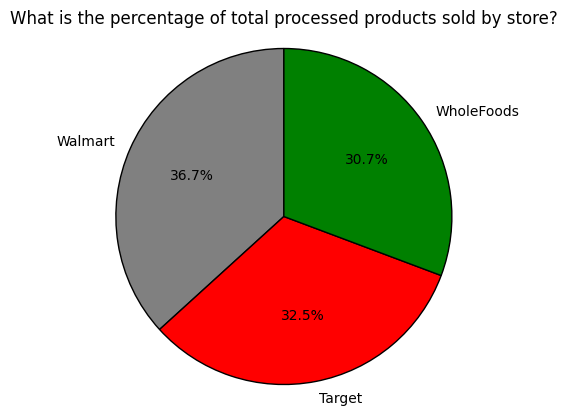

In [49]:
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['grey', 'red', 'green'],
       wedgeprops={'edgecolor': 'black'})
plt.title("What is the percentage of total processed products sold by store?")
plt.axis('equal')
plt.ylabel("")
plt.show()

In [50]:
organic

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,...,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins,Food or Drink
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,...,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,...,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,...,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26145,Organic Dark Roasted Creamy Peanut Butter Spre...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.488,2.0,6.69,0.00,453.59,25.00,...,15.62,3.12,9.38,0.17,0.00,Processed foods,Processed Food,Organic,1,Food
26146,Organic Dark Roasted Crunchy Peanut Butter Spr...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.477,2.0,6.69,0.00,453.59,24.24,...,15.15,3.03,9.09,0.15,0.00,Processed foods,Processed Food,Organic,1,Food
26177,"Organic Sunflower Butter, 16 oz",WholeFoods,spread-squeeze,SunButter,0.168,0.0,8.99,0.00,453.59,21.88,...,15.62,3.12,9.38,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,0,Food
26208,"Nutiva Organic Hazelnut Spread, Dark Chocolate...",Walmart,spread-squeeze,Nutiva,0.443,0.0,4.97,0.00,368.54,8.11,...,48.65,32.43,18.92,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food


In [51]:
OrganicTarget = organic[organic["store"] == "Target"]

In [52]:
OrganicTarget

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,...,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins,Food or Drink
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,...,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,...,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,...,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25118,Amy&#39;s Organic Low Fat Alphabet Soup - 14.1oz,Target,soup-stew,Amy's,0.643,3.0,2.49,0.02,399.73,0.75,...,5.25,1.50,0.50,0.17,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food
25138,Amy&#39;s Organic Low Fat Cream of Tomato Soup...,Target,soup-stew,Amy's,0.812,3.0,2.49,0.02,411.07,0.73,...,5.60,3.65,0.73,0.21,0.00,Ultra-processed food and drink products,Processed Food,Organic,3,Food
25147,Progresso Organic Black Bean Soup 14.3oz,Target,soup-stew,Progresso,0.627,2.0,2.59,0.01,405.40,2.73,...,10.94,1.56,2.34,0.26,0.00,Processed foods,Processed Food,Organic,2,Food
25148,Pacific Foods Organic Unsalted Chicken Culinar...,Target,soup-stew,Pacific Foods,0.621,3.0,4.69,0.25,907.18,2.50,...,0.42,0.00,0.00,0.03,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food


In [53]:
organic

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,...,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins,Food or Drink
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,...,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,...,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,...,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26145,Organic Dark Roasted Creamy Peanut Butter Spre...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.488,2.0,6.69,0.00,453.59,25.00,...,15.62,3.12,9.38,0.17,0.00,Processed foods,Processed Food,Organic,1,Food
26146,Organic Dark Roasted Crunchy Peanut Butter Spr...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.477,2.0,6.69,0.00,453.59,24.24,...,15.15,3.03,9.09,0.15,0.00,Processed foods,Processed Food,Organic,1,Food
26177,"Organic Sunflower Butter, 16 oz",WholeFoods,spread-squeeze,SunButter,0.168,0.0,8.99,0.00,453.59,21.88,...,15.62,3.12,9.38,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,0,Food
26208,"Nutiva Organic Hazelnut Spread, Dark Chocolate...",Walmart,spread-squeeze,Nutiva,0.443,0.0,4.97,0.00,368.54,8.11,...,48.65,32.43,18.92,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food


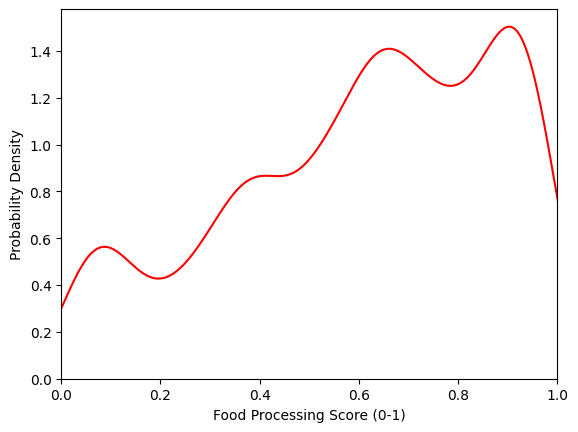

In [54]:
sns.kdeplot(organic["Food Processing Score"], color="red")
plt.xlabel("Food Processing Score (0-1)")
plt.xlim(0, 1)
plt.ylabel("Probability Density")
plt.show()

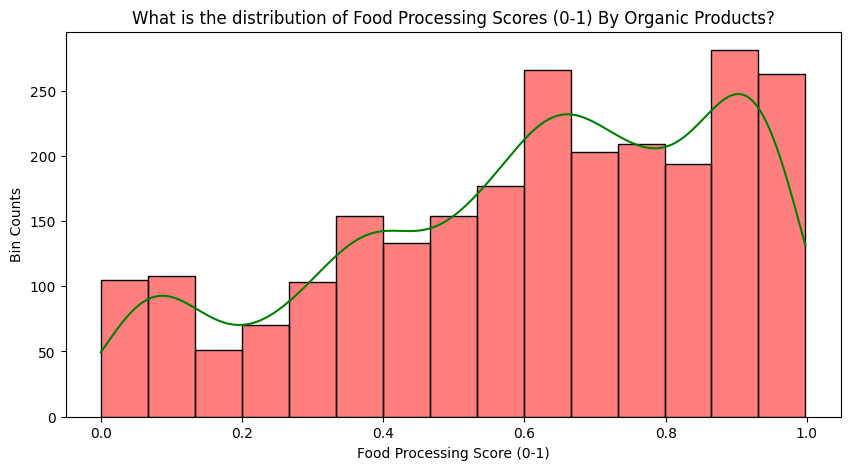

In [55]:
plt.figure(figsize=(10, 5))
plt.title("What is the distribution of Food Processing Scores (0-1) By Organic Products?")
sns.histplot(organic["Food Processing Score"], bins=15, color="red", edgecolor="black", kde=True)

ax = plt.gca()
for line in ax.lines:
    line.set_color("green")

plt.xlabel("Food Processing Score (0-1)")
plt.ylabel("Bin Counts")
plt.show()

In [56]:
organic["Food Processing Score"].median()

0.648

In [57]:
organic["Food Processing Score"].mean().round(3)

0.607

In [58]:
organic

,name,store,category,brand,Food Processing Score,Food Processing Classification Group,price,Price Per Calorie,package_weight,Protein,...,Carbohydrate,Total Sugar Content,Dietary Fiber Content,Sodium,Cholesterol,Food Processing Group,Processed Food or Non Processed Food,Organic,Food Processing Score Bins,Food or Drink
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815,3.0,5.29,0.04,396.89,5.05,...,12.12,9.09,0.00,0.08,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583,3.0,2.79,0.06,90.72,1.10,...,13.19,7.69,2.20,0.01,0.00,Ultra-processed food and drink products,Processed Food,Organic,2,Food
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451,0.0,2.49,0.02,90.72,5.49,...,15.38,8.79,3.30,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.774,3.0,4.99,0.02,396.89,3.03,...,14.14,6.06,2.02,0.05,0.01,Ultra-processed food and drink products,Processed Food,Organic,3,Food
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26145,Organic Dark Roasted Creamy Peanut Butter Spre...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.488,2.0,6.69,0.00,453.59,25.00,...,15.62,3.12,9.38,0.17,0.00,Processed foods,Processed Food,Organic,1,Food
26146,Organic Dark Roasted Crunchy Peanut Butter Spr...,WholeFoods,spread-squeeze,Santa Cruz Organic,0.477,2.0,6.69,0.00,453.59,24.24,...,15.15,3.03,9.09,0.15,0.00,Processed foods,Processed Food,Organic,1,Food
26177,"Organic Sunflower Butter, 16 oz",WholeFoods,spread-squeeze,SunButter,0.168,0.0,8.99,0.00,453.59,21.88,...,15.62,3.12,9.38,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,0,Food
26208,"Nutiva Organic Hazelnut Spread, Dark Chocolate...",Walmart,spread-squeeze,Nutiva,0.443,0.0,4.97,0.00,368.54,8.11,...,48.65,32.43,18.92,0.00,0.00,Unprocessed or minimally processed foods,Unprocessed Food,Organic,1,Food


In [59]:
organic["store"].value_counts()

store
WholeFoods    2005
Target         298
Walmart        168
Name: count, dtype: int64

**Filte for Organic Food Only Sold at Whole and Visualize the distrubtion of data**

**Visualize histogram with kde plot for all organic foods sold at Whole Foods**

In [60]:
OrganicWholeFoods = organic[organic["store"] == "WholeFoods"]

In [61]:
ScoreBins = np.linspace(0, 1, 16)
red_shades = sns.color_palette("Reds", n_colors=len(ScoreBins))
bin_labels = [f'{ScoreBins[i]:.2f}-{ScoreBins[i+1]:.2f}' for i in range(len(ScoreBins)-1)]

In [62]:
OrganicWholeFoods['ScoreBins'] = pd.cut(OrganicWholeFoods['Food Processing Score'], bins=ScoreBins, labels=bin_labels, include_lowest=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_53884\1876306589.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  OrganicWholeFoods['ScoreBins'] = pd.cut(OrganicWholeFoods['Food Processing Score'], bins=ScoreBins, labels=bin_labels, include_lowest=True)


C:\Users\alexh\AppData\Local\Temp\ipykernel_53884\3065047211.py:2: UserWarning: The palette list has more values (16) than needed (15), which may not be intended.
  sns.histplot(OrganicWholeFoods, x='Food Processing Score', hue='ScoreBins', palette=red_shades, fill=True, legend=False, multiple="stack", bins=ScoreBins)


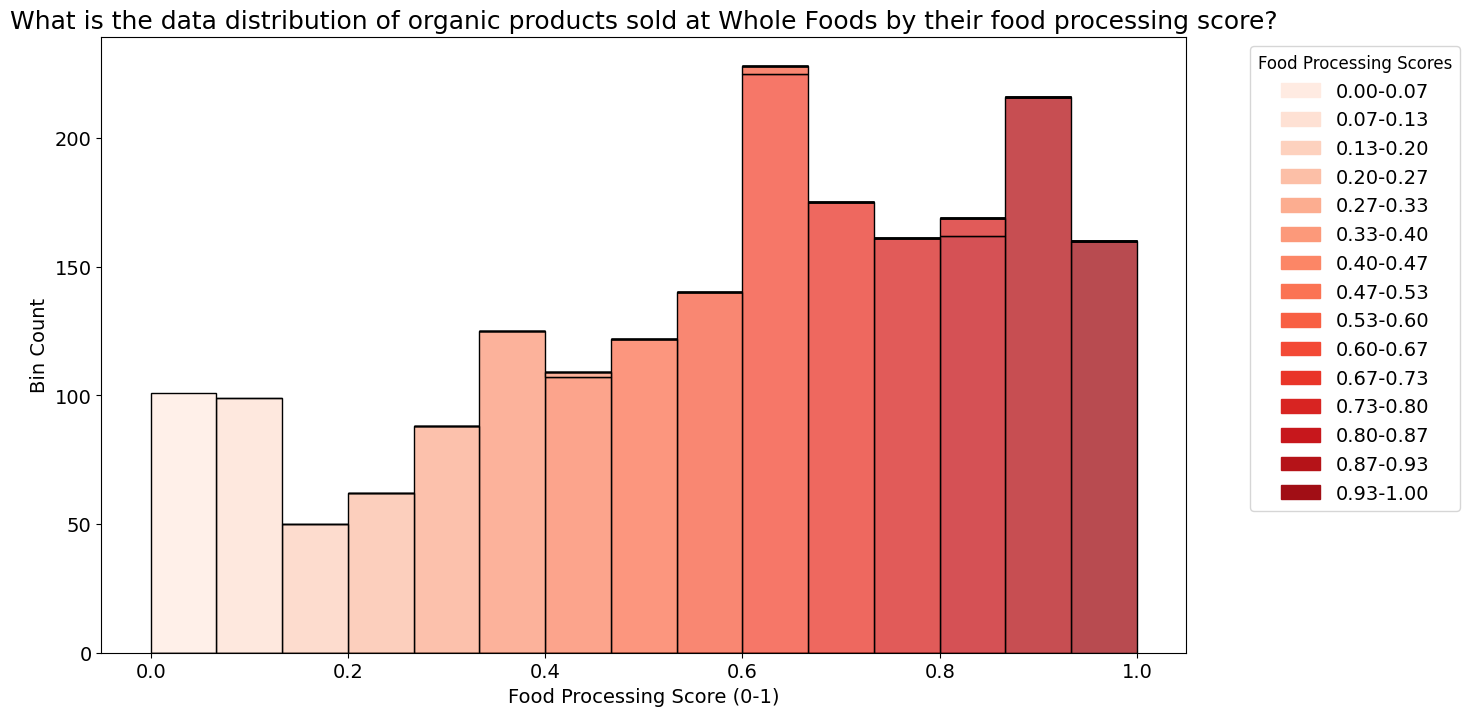

In [63]:
fig, ax = plt.subplots(figsize=(14, 8))
sns.histplot(OrganicWholeFoods, x='Food Processing Score', hue='ScoreBins', palette=red_shades, fill=True, legend=False, multiple="stack", bins=ScoreBins)
ax.set_title("What is the data distribution of organic products sold at Whole Foods by their food processing score?", fontsize=18)
ax.set_xlabel("Food Processing Score (0-1)", fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_ylabel("Bin Count", fontsize=14)
handles = [mpatches.Patch(color=red_shades[i], label=label) for i, label in enumerate(bin_labels)]
ax.legend(handles=handles, title='Food Processing Scores', fontsize=14, title_fontsize="large", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()